# Deliverable 1: the mathematical model of the delivery routing problem

**CesiCDP for the ADEME Smart Multimodal Mobility call.** Team: Pablo, Dag, Farida.

This notebook states the **integer linear program** (ILP) of our problem: the data we use, the
decisions the model takes, what it minimizes and the rules it must respect. Each formula is
explained and checked with numbers on a small example.

| Section | Content |
| --- | --- |
| 1 | The problem |
| 2 | Data, including the traffic matrix |
| 3 | Decision variables |
| 4 | Objective function |
| 5 | Constraints |
| 6 | The complete model |
| 7 | Check on a toy instance |
| 8 | Modeling choices: waiting, Hamiltonian cycles, complexity |

## 1. The problem

CesiCDP answers the ADEME call on *Smart Multimodal Mobility* with **delivery route
management**: the same deliveries with less driving, and less driving in traffic, burn less fuel.

*One depot, $K$ identical trucks, a list of customers. Which truck serves which customers, in which
order, and when does each truck leave, so that every customer is delivered and the total working
time of the trucks is minimal?*

Constraints kept from the brief: **capacity** of the trucks (Level B, CVRP), **time windows** with
waiting allowed (Level A, CVRPTW), and **traffic** depending on the hour.

## 2. Data

The road network is reduced to a **complete directed graph** on the depot and the customers: the
time of each trip $i \to j$ is the fastest path in the network, computed once. The depot appears
twice, node $0$ (departure) and node $n + 1$ (return), so that each truck has a departure time and
a return time.

| Symbol | Meaning | Toy instance |
| --- | --- | --- |
| $V^+ = \{1, \dots, n\}$ | customers | 6 customers |
| $V = \{0\} \cup V^+ \cup \{n+1\}$ | all nodes; $0$ and $n+1$ are the depot | $\{0, \dots, 7\}$ |
| $A$ | allowed trips: depot to customer, customer to customer, customer to depot, and $0 \to n+1$ (truck not used) | 43 arcs |
| $\mathcal{K} = \{1, \dots, K\}$ | trucks | 3 |
| $Q$ | capacity of one truck | 10 |
| $q_i$ | demand of customer $i$ | 3 to 5 |
| $[e_i, l_i]$ | time window: service must **start** in it | e.g. 9:00 to 10:00 |
| $s_i$ | service (unloading) time | 10 min |
| $[e_0, l_0]$ | working day of the depot | 6:00 to 20:00 |
| $\mathcal{H} = \{0, \dots, 23\}$ | hours of the day | |
| $c_{ij}^h$ | **traffic matrix**: travel time from $i$ to $j$ when leaving during hour $h$ | see below |

All times are in minutes after midnight (8:00 is 480).

### The traffic matrix

The travel time of a trip depends only on the **hour of departure**: for each hour $h$ we have a
number $c_{ij}^h$. We build it from the travel time on empty roads, $c_{ij}$, and one intensity per
hour, $\rho_h$:

$$
c_{ij}^h = \rho_h \cdot c_{ij} = \underbrace{c_{ij}}_{\text{empty road}} + \underbrace{(\rho_h - 1)\, c_{ij}}_{\text{traffic delay}}
$$

Example: a 10-minute trip takes $10 + 0.8 \times 10 = 18$ minutes when leaving at 8:00.

| $h$ | 0 to 4 | 5 | 6 | **7** | **8** | 9 | 10 to 15 | 16 | **17** | **18** | 19 | 20, 21 | 22, 23 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| $\rho_h$ | 1.00 | 1.05 | 1.30 | **1.75** | **1.80** | 1.40 | 1.20 to 1.30 | 1.45 | **1.80** | **1.75** | 1.40 | 1.10, 1.05 | 1.00 |

Peaks from 7:00 to 9:00 and from 17:00 to 19:00, a shoulder hour before and after each, a moderate
day, free roads at night. These values are assumptions, to be replaced by measured data (e.g. the
TomTom Traffic Index). The matrix is **data**: the model only reads a number from it. Seen as a
graph, it is 24 copies of the same graph with different weights, one per hour.

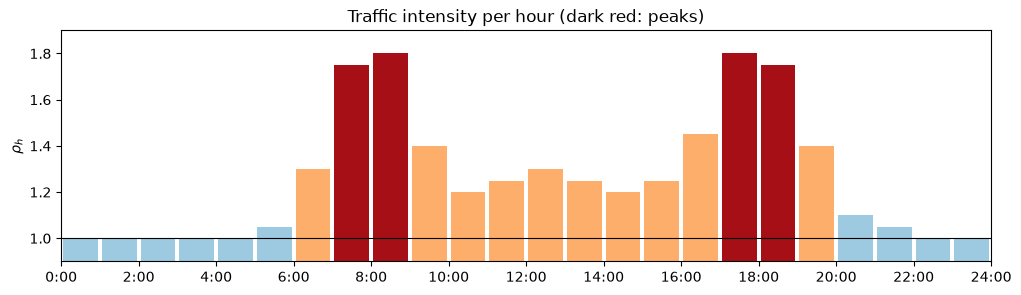

customers:
   q_i          window
1    4  08:00 to 09:00
2    4  08:00 to 11:00
3    3  07:00 to 08:00
4    3  09:00 to 10:00
5    5  10:00 to 14:00
6    5  10:00 to 14:00

example of the matrix: trip 3 -> 4 (c_34 = 10 min) takes 10 min leaving at 3:00, 18 min at 8:00, 13 min at 12:00


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.precision", 2)
pd.set_option("display.width", 200)


def hhmm(t: float) -> str:
    # Minutes after midnight -> "HH:MM", or "HH:MM:SS" when not a whole minute (462.5 -> "07:42:30").
    sec = round(t * 60)
    hm = f"{sec // 3600:02d}:{sec // 60 % 60:02d}"
    return hm if sec % 60 == 0 else f"{hm}:{sec % 60:02d}"


# ---- toy instance: row i is node i; node 0 = depot (departure), node 7 = depot (return)
coords = np.array([[0, 0], [1, 0], [2, 0], [0, 1], [0, 2], [-1, 0], [0, -1], [0, 0]], dtype=float)
RET = 7
q = np.array([0, 4, 4, 3, 3, 5, 5, 0])                                    # demands q_i
Q, K = 10, 3                                                              # capacity, trucks
s = np.array([0, 10, 10, 10, 10, 10, 10, 0], dtype=float)                 # service times s_i
e = np.array([360, 480, 480, 420, 540, 600, 600, 360], dtype=float)       # window opens e_i
l = np.array([1200, 540, 660, 480, 600, 840, 840, 1200], dtype=float)     # window closes l_i
c = 10 * np.linalg.norm(coords[:, None] - coords[None], axis=2)           # empty-road time c_ij (min)

# traffic: intensity per hour, and the matrix C[i, j, h] = rho_h * c_ij
RHO = np.array([1.00, 1.00, 1.00, 1.00, 1.00, 1.05, 1.30, 1.75, 1.80, 1.40, 1.20, 1.25,
                1.30, 1.25, 1.20, 1.25, 1.45, 1.80, 1.75, 1.40, 1.10, 1.05, 1.00, 1.00])
C = c[:, :, None] * RHO[None, None, :]

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(np.arange(24) + 0.5, RHO, width=0.9,
       color=["#a50f15" if r > 1.5 else "#fdae6b" if r > 1.1 else "#9ecae1" for r in RHO])
ax.axhline(1, color="k", lw=0.8)
ax.set_xticks(range(0, 25, 2), [f"{h}:00" for h in range(0, 25, 2)])
ax.set(xlim=(0, 24), ylim=(0.9, 1.9), ylabel=r"$\rho_h$", title="Traffic intensity per hour (dark red: peaks)")
plt.show()

print("customers:", pd.DataFrame({"q_i": q[1:RET], "window": [f"{hhmm(a)} to {hhmm(b)}" for a, b in zip(e[1:RET], l[1:RET])]},
                                 index=range(1, RET)).to_string(), sep="\n")
print(f"\nexample of the matrix: trip 3 -> 4 (c_34 = {c[3, 4]:.0f} min) takes "
      f"{C[3, 4, 3]:.0f} min leaving at 3:00, {C[3, 4, 8]:.0f} min at 8:00, {C[3, 4, 12]:.0f} min at 12:00")

## 3. Decision variables

**Decision variables** are the unknowns the model chooses; everything in section 2 is given.

| Variable | Type | Meaning |
| --- | --- | --- |
| $x_{ij}^k$ | binary | 1 if truck $k$ drives directly from $i$ to $j$ |
| $y_{ih}$ | binary | 1 if the truck that serves customer $i$ **leaves** it during hour $h$ |
| $y_{0h}^k$ | binary | 1 if truck $k$ leaves the depot during hour $h$ |
| $t_0^k$, $t_{n+1}^k$ | real $\ge 0$ | time truck $k$ **leaves** the depot, time it is **back** |
| $a_i$ | real $\ge 0$ | arrival time at customer $i$ |
| $w_i$ | real $\ge 0$ | waiting time in front of customer $i$ |
| $t_i$ | real $\ge 0$ | time service starts at customer $i$ |

**Why these and not others.**

- **$x_{ij}^k$ has a truck index** so that each truck has its own departure time, its own cost and
  its own load.
- **$y$ picks the hour of departure**, i.e. which number of the traffic matrix applies. Since a
  customer is served once, one hour per customer is enough; the depot needs one per truck.
- **Times per customer, not per truck**: a customer has one truck, so one arrival, one wait and one
  start are enough.
- **No load variable** ("load delivered", "load on board"): trucks only deliver, so a truck is
  fullest when it leaves the depot; checking the load there is enough (constraint (5)).

Shorthands used below: $t_i^k$ is $t_i$ at a customer and $t_0^k$ at the depot; $a_j^k$ is $a_j$ at a
customer and $t_{n+1}^k$ at the return depot; $y_{ih}^k$ is $y_{ih}$ at a customer and $y_{0h}^k$ at
the depot.

## 4. Objective function

$$
\min \ z = \sum_{k \in \mathcal{K}} \big( t_{n+1}^k - t_0^k \big)
$$

**In words.** Minimize the **total route duration** of the fleet: for each truck, the time from the
moment it leaves the depot to the moment it is back, added over all trucks. This is the objective
stated in the brief ("minimizing the total route duration"), and it has a single component.

| Symbol | Meaning | Toy |
| --- | --- | --- |
| $k \in \mathcal{K}$ | one truck; $\sum_{k \in \mathcal{K}}$ adds truck 1, truck 2, ..., truck $K$ | 3 trucks |
| $t_0^k$ | time truck $k$ leaves the depot (variable) | truck 2: 7:42:30 |
| $t_{n+1}^k$ | time truck $k$ is back at the depot (variable) | truck 2: 9:38 |
| $t_{n+1}^k - t_0^k$ | **route duration** of truck $k$: back **minus** leaves | truck 2: $115.5$ min |
| $z$ | total route duration of the fleet, in minutes | $80 + 115.5 + 61 = 256.5$ |

**What a route duration contains.** Every minute between leaving and coming back is one of three
things, so the single component already counts all of them:

| Inside the route duration | Where it comes from | Truck 2 |
| --- | --- | --- |
| driving, **traffic included** | each trip takes $c_{ij}^h$, the matrix value at its departure hour (constraint (8)) | $17.5 + 18 + 28 = 63.5$ |
| unloading | $s_i$ at each customer served | $10 + 10 = 20$ |
| **waiting** | $w_i$ in front of a customer not open yet (constraint (9)) | $32$ |
| **total** | | $115.5$ |

So traffic and waiting are both **in** the objective: a trip in the peak or a wait at a closed
customer makes the truck come back later, which increases $z$. Unloading is the same in every plan,
so it never changes which plan is best.

It is **linear**: a difference of two variables per truck. An unused truck ($0 \to n + 1$) leaves
and returns at the same moment, so it adds 0.

## 5. Constraints

**Routing**

$$
\begin{aligned}
& \sum_{k \in \mathcal{K}} \sum_{j : (i, j) \in A} x_{ij}^k = 1 && \forall i \in V^+ && \text{(1) each customer served once, by one truck}\\
& \sum_{j : (0, j) \in A} x_{0j}^k = 1 && \forall k \in \mathcal{K} && \text{(2) each truck leaves the depot once}\\
& \sum_{i : (i, j) \in A} x_{ij}^k = \sum_{i : (j, i) \in A} x_{ji}^k && \forall j \in V^+,\ k \in \mathcal{K} && \text{(3) a truck that enters a customer leaves it}\\
& \sum_{i : (i, n+1) \in A} x_{i, n+1}^k = 1 && \forall k \in \mathcal{K} && \text{(4) each truck comes back}
\end{aligned}
$$

A truck that drives $0 \to n+1$ is not used, so (2) and (4) also allow fewer than $K$ trucks.

**Capacity**

$$
\sum_{i \in V^+} q_i \sum_{j : (i, j) \in A} x_{ij}^k \le Q \qquad \forall k \in \mathcal{K} \qquad \text{(5)}
$$

The left side is the load of truck $k$ when it leaves the depot.

**Time with traffic**

$$
\begin{aligned}
& \sum_{h \in \mathcal{H}} y_{ih}^k = 1 && \forall i \in V^+ \cup \{0\},\ k \in \mathcal{K} && \text{(6) one departure hour}\\
& \sum_{h \in \mathcal{H}} 60h \, y_{ih}^k \ \le\ t_i^k + s_i \ \le\ \sum_{h \in \mathcal{H}} 60(h+1)\, y_{ih}^k && \forall i \in V^+ \cup \{0\},\ k \in \mathcal{K} && \text{(7) the departure is in that hour}\\
& \Big\lvert\, a_j^k - t_i^k - s_i - \sum_{h \in \mathcal{H}} c_{ij}^h \, y_{ih}^k \,\Big\rvert \ \le\ M\,(1 - x_{ij}^k) && \forall (i, j) \in A,\ k \in \mathcal{K} && \text{(8) arrival = departure + travel time of that hour}
\end{aligned}
$$

- $t_i^k + s_i$ is the moment the truck leaves $i$ (end of service; $s_0 = 0$).
- (6) and (7): exactly one $y$ equals 1, and it is the hour that contains the departure. The sums
  then just pick that hour: $\sum_h 60h\, y_{ih} = 60 \times$ the chosen hour.
- (8): $\sum_h c_{ij}^h y_{ih}^k$ reads the matrix at the chosen hour. $M$ is a large number (two
  days, 2880 min). If truck $k$ drives $i \to j$, the right side is 0 and the arrival is exactly
  departure + travel time; otherwise the right side is $M$ and the rule is switched off. The
  absolute value is short for two linear inequalities ($\le$ and $\ge$).

**Waiting and time windows**

$$
\begin{aligned}
& t_i = a_i + w_i && \forall i \in V^+ && \text{(9) wait, then serve}\\
& e_i \le t_i \le l_i,\quad t_0^k \ge e_0,\quad t_{n+1}^k \le l_0 && \forall i \in V^+,\ k \in \mathcal{K} && \text{(10) windows and working day}\\
& x_{ij}^k,\ y_{ih}^k \in \{0, 1\},\quad a_i,\ w_i,\ t_i,\ t_0^k,\ t_{n+1}^k \ge 0 && && \text{(11) domains}
\end{aligned}
$$

A truck that arrives before the window opens waits ($w_i > 0$); a truck may never start after $l_i$.

## 6. The complete model

$$
\begin{aligned}
\min \quad & \sum_{k \in \mathcal{K}} \big( t_{n+1}^k - t_0^k \big) \\[4pt]
\text{s.t.} \quad
& \sum_{k} \sum_{j} x_{ij}^k = 1 && \forall i \in V^+ && \text{(1)}\\
& \sum_{j} x_{0j}^k = 1, \quad \sum_{i} x_{i, n+1}^k = 1 && \forall k && \text{(2), (4)}\\
& \sum_{i} x_{ij}^k = \sum_{i} x_{ji}^k && \forall j \in V^+,\ k && \text{(3)}\\
& \sum_{i \in V^+} q_i \sum_{j} x_{ij}^k \le Q && \forall k && \text{(5)}\\
& \sum_h y_{ih}^k = 1, \quad \sum_h 60h\, y_{ih}^k \le t_i^k + s_i \le \sum_h 60(h+1)\, y_{ih}^k && \forall i \in V^+ \cup \{0\},\ k && \text{(6), (7)}\\
& \Big\lvert\, a_j^k - t_i^k - s_i - \sum_h c_{ij}^h\, y_{ih}^k \,\Big\rvert \le M (1 - x_{ij}^k) && \forall (i, j) \in A,\ k && \text{(8)}\\
& t_i = a_i + w_i, \quad e_i \le t_i \le l_i && \forall i \in V^+ && \text{(9), (10)}\\
& t_0^k \ge e_0, \quad t_{n+1}^k \le l_0 && \forall k && \text{(10)}\\
& x,\ y \in \{0, 1\}, \quad a,\ w,\ t \ge 0 && && \text{(11)}
\end{aligned}
$$

Every line is a sum of variables multiplied by numbers: the model is a **mixed integer linear
program**. Size: $K \lvert A \rvert$ variables $x$, $24 (n + K)$ variables $y$, $3n + 2K$ real
variables (toy: 129, 216 and 24). Without traffic ($\rho_h = 1$) it is the classic CVRPTW; with wide
windows, the CVRP.

**Simplification we accept.** The travel time is fixed by the hour of **departure**, even if the trip
ends in the next hour. Near a full hour this can be unrealistic (leaving at 8:59 is charged the peak,
leaving at 9:00 is not). It keeps the model simple; a finer version would cut the trip at each full
hour.

## 7. Check on the toy instance

One solution: truck 1 serves customers 1 and 2, truck 2 serves 3 and 4, truck 3 serves 5 and 6. We
apply constraints (6) to (10) along each route, with the best departure time of each truck.

In [2]:
routes = {1: [1, 2], 2: [3, 4], 3: [5, 6]}  # truck k -> customers in visiting order


def schedule(route: list[int], t0: float):
    # Constraints (6) to (10) along 0 -> route -> 7, leaving the depot at t0.
    # Returns one row per trip, or None if a time window is missed.
    rows, i, t_i = [], 0, t0
    for j in route + [RET]:
        leave = t_i + s[i]
        h = int(leave // 60)                                  # (6), (7): hour of departure
        travel = C[i, j, h]                                   # (8): read the matrix at that hour
        arrive = leave + travel
        start = arrive if j == RET else max(arrive, e[j])     # (9), (10): wait if early
        if start > l[j]:
            return None
        rows.append(dict(trip=f"{i} -> {j}", leave=leave, hour=h, travel=travel,
                         arrive=arrive, wait=start - arrive, start=start))
        i, t_i = j, start
    return rows


rows = []
for k, r in routes.items():
    shift, t0 = min((sch[-1]["arrive"] - d, d) for d in np.arange(e[0], l[0], 0.25) if (sch := schedule(r, d)))
    rows += [dict(truck=k, **row) for row in schedule(r, t0)]
df = pd.DataFrame(rows)
show = df.copy()
for col in ["leave", "arrive", "start"]:
    show[col] = show[col].map(hhmm)
show

,truck,trip,leave,hour,travel,arrive,wait,start
0,1,0 -> 1,08:32,8,18.00,08:50,0.0,08:50
1,1,1 -> 2,09:00,9,14.00,09:14,0.0,09:14
2,1,2 -> 7,09:24,9,28.00,09:52,0.0,09:52
3,2,0 -> 3,07:42:30,7,17.50,08:00,0.0,08:00
4,2,3 -> 4,08:10,8,18.00,08:28,32.0,09:00
5,2,4 -> 7,09:10,9,28.00,09:38,0.0,09:38
6,3,0 -> 5,10:00,10,12.00,10:12,0.0,10:12
7,3,5 -> 6,10:22,10,16.97,10:38:58,0.0,10:38:58
8,3,6 -> 7,10:48:58,10,12.00,11:00:58,0.0,11:00:58


In [3]:
summary = df.groupby("truck").agg(leaves_depot=("leave", "first"), back_at_depot=("arrive", "last"),
                                  driving=("travel", "sum"), waiting=("wait", "sum"))
summary["unloading"] = [s[r].sum() for r in routes.values()]
summary["shift"] = summary.back_at_depot - summary.leaves_depot
summary["load"] = [q[r].sum() for r in routes.values()]
print(f"objective z = total route duration = {summary['shift'].sum():.1f} min "
      f"= driving {summary.driving.sum():.1f} + unloading {summary.unloading.sum():.0f} + waiting {summary.waiting.sum():.0f}")
summary.assign(leaves_depot=summary.leaves_depot.map(hhmm), back_at_depot=summary.back_at_depot.map(hhmm))

objective z = total route duration = 256.5 min = driving 164.5 + unloading 60 + waiting 32


,leaves_depot,back_at_depot,driving,waiting,unloading,shift,load
truck,,,,,,,
1,08:32,09:52,60.00,0.0,20.0,80.00,8
2,07:42:30,09:38,63.50,32.0,20.0,115.50,6
3,10:00,11:00:58,40.97,0.0,20.0,60.97,10


**Reading the result.** Truck 2 must start customer 3 before 8:00 and customer 4 after 9:00: it
waits 32 minutes in front of customer 4; those 32 minutes are inside its route duration, so they
are counted in $z$. Loads 8, 6 and 10 respect $Q = 10$. Checks of each constraint:

| Constraint | Example on the solution | Holds |
| --- | --- | --- |
| (1) to (4) | each customer has one truck; each truck leaves 0 once and reaches 7 once | yes |
| (5) | loads $8, 6, 10 \le 10$ | yes |
| (6), (7) | truck 2 leaves customer 3 at 8:10, so $y_{3,8} = 1$ and $480 \le 490 \le 540$ | yes |
| (8) | $a_4 = 490 + c_{34}^8 = 490 + 1.8 \times 10 = 508$ (8:28) | yes |
| (9) | $t_4 = a_4 + w_4 = 508 + 32 = 540$ | yes |
| (10) | $540 \in [540, 600]$; every truck leaves after 6:00 and is back before 20:00 | yes |

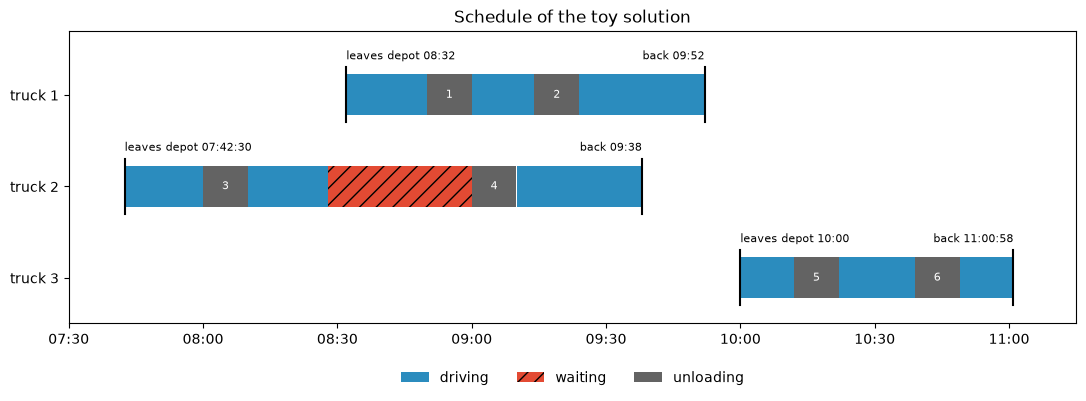

In [4]:
fig, ax = plt.subplots(figsize=(13, 3.8))
for k in routes:
    leave, back = summary.loc[k, "leaves_depot"], summary.loc[k, "back_at_depot"]
    for t, label, ha in [(leave, f"leaves depot {hhmm(leave)}", "left"), (back, f"back {hhmm(back)}", "right")]:
        ax.plot([t / 60] * 2, [k - 0.3, k + 0.3], color="k", lw=1.5)
        ax.text(t / 60, k - 0.36, label, ha=ha, va="bottom", fontsize=8)
for row in df.itertuples():
    ax.barh(row.truck, row.travel / 60, left=row.leave / 60, color="#2b8cbe", height=0.45)
    if row.wait > 0:
        ax.barh(row.truck, row.wait / 60, left=row.arrive / 60, color="#e34a33", height=0.45, hatch="//")
    j = int(row.trip.split("->")[1])
    if j != RET:
        ax.barh(row.truck, s[j] / 60, left=row.start / 60, color="#636363", height=0.45)
        ax.text(row.start / 60 + s[j] / 120, row.truck, str(j), ha="center", va="center", color="white", fontsize=8)
for col, lab, hatch in [("#2b8cbe", "driving", None), ("#e34a33", "waiting", "//"), ("#636363", "unloading", None)]:
    ax.barh(0, 0, color=col, hatch=hatch, label=lab)
ax.set_yticks([1, 2, 3], ["truck 1", "truck 2", "truck 3"])
ax.set_ylim(0.3, 3.5)
ax.invert_yaxis()
ax.set_xlim(7.5, 11.25)
ax.set_xticks(np.arange(7.5, 11.5, 0.5), [hhmm(60 * x) for x in np.arange(7.5, 11.5, 0.5)])
ax.set_title("Schedule of the toy solution")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.show()

## 8. Modeling choices

**Why a driver may wait.** If a truck arrives before a customer opens, forbidding it would reject
plans a driver can execute, and serving early is impossible (nobody receives the goods). So the
truck waits, as the brief allows ("waiting on site allowed until the window opens"). Waiting is part
of the route duration, so it is paid in the objective and only appears when a window forces it. Waiting at
the depot is not counted: the shift starts when the truck leaves, and each truck chooses its
departure (truck 1 leaving at 7:30 instead of 8:32 would cost 104 minutes instead of 80).

**Is a route a Hamiltonian cycle?** Ideally yes: the truck passes each of its customers once and
returns. On a real map it may pass the same place twice (a dead-end street, customers on the same
road: in the toy, truck 1 passes customer 1 again on its way back from customer 2), and that is
fine. The model only fixes how many times a customer is **served** (once, constraint (1)); passing
through a place is hidden inside the travel time of an arc. In the model's graph each route is a
cycle on the depot and its customers; the whole solution is several cycles sharing the depot.
Waiting has nothing to do with it: the cycle is about the order, waiting about the time.

**Complexity.** With one truck, no capacity limit, no windows and no traffic, the problem is the
travelling salesman problem, which is NP-hard (it contains the Hamiltonian cycle problem, Karp
1972). Our problem contains it as a special case ($K = 1$, $Q \ge \sum q_i$, wide windows,
$\rho_h = 1$), so it is **NP-hard**: no exact algorithm is expected to solve large instances in
reasonable time, which is why the solving method will be a **metaheuristic**.

**References.** Dantzig and Ramser (1959), *The Truck Dispatching Problem*; Toth and Vigo (2014),
*Vehicle Routing*, SIAM; Cordeau et al. (2002), *VRP with Time Windows*; Ichoua, Gendreau and Potvin
(2003), *Vehicle dispatching with time-dependent travel times*; Karp (1972), *Reducibility among
combinatorial problems*; TomTom Traffic Index.